MODULO 3 PROGETTO 1

1. Data Exploration & Preprocessing

Caricamento e Analisi: Caricare il dataset e fornire un'analisi descrittiva iniziale (es. df.describe()).Standardizzazione: Applicare la standardizzazione alle feature ($X$) per garantire che tutti gli attributi abbiano media zero e deviazione standard unitaria.

In [24]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

In [25]:
iris = load_iris()

X = iris.data
feature_names =iris.feature_names
print(iris.DESCR)



.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [26]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)


STIMA DI K CON DBSCAN 

In [27]:
lista_eps = [0.35, 0.45, 0.55]

min_samples = 5
for eps in lista_eps:
    dbscan = DBSCAN(
    min_samples = min_samples,
    eps = eps
    )
    dbscan.fit(X_std)
    labels = dbscan.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"Numero di cluster trovati: {n_clusters} con eps: {eps}")
    assigned = np.sum(labels != -1)
    tot = len(labels)
    noise = tot - assigned
    print(f"Campioni assegnati: {assigned}, rumore individuato:{noise}, % di clustering: {assigned/tot * 100:.2f}%")


Numero di cluster trovati: 4 con eps: 0.35
Campioni assegnati: 46, rumore individuato:104, % di clustering: 30.67%
Numero di cluster trovati: 3 con eps: 0.45
Campioni assegnati: 96, rumore individuato:54, % di clustering: 64.00%
Numero di cluster trovati: 2 con eps: 0.55
Campioni assegnati: 121, rumore individuato:29, % di clustering: 80.67%


STIMA DI K CON ELBOW METHOD 

In [28]:
wcss = []
k_values = range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters = k, init = "k-means++", random_state = 42)
    kmeans.fit(X_std)
    wcss.append(kmeans.inertia_)

c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: 

GRAFICO DELL'ELBOW METHOD PER INDIVIDUARE IL PUNTO DI GOMITO

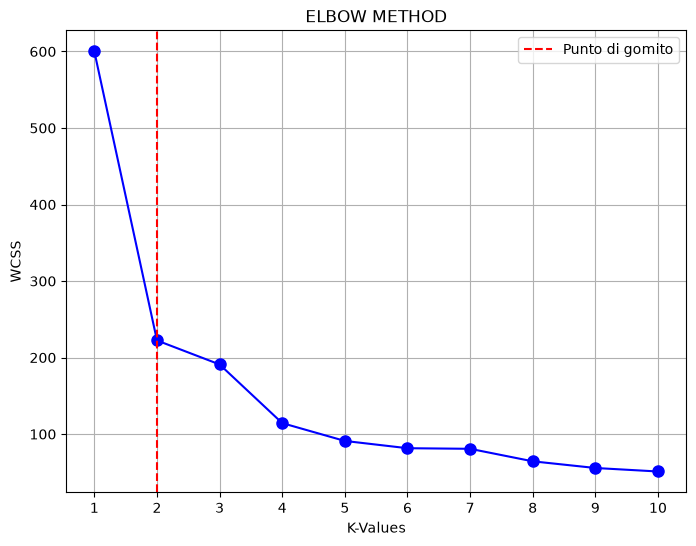

In [32]:
plt.figure(figsize=(8,6))
plt.plot(k_values, wcss, "o-", color = "blue", markersize = 8)
plt.xlabel("K-Values")
plt.ylabel("WCSS")
plt.xticks(k_values)
plt.title("ELBOW METHOD")
plt.grid(True)
plt.axvline( x= 2, color = "red", linestyle = "--", label = "Punto di gomito")
plt.legend()
plt.show()

APPLICAZIONE FINALE 

In [33]:
kmeans_finale = KMeans(n_clusters = 2, init = "k-means++", random_state = 42)
kmeans_labels= kmeans_finale.fit_predict(X_std)
score = silhouette_score(X_std, kmeans_labels)
print(f"Il silhouette score di K = 2 è: {score:.3f}")


Il silhouette score di K = 2 è: 0.582


c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


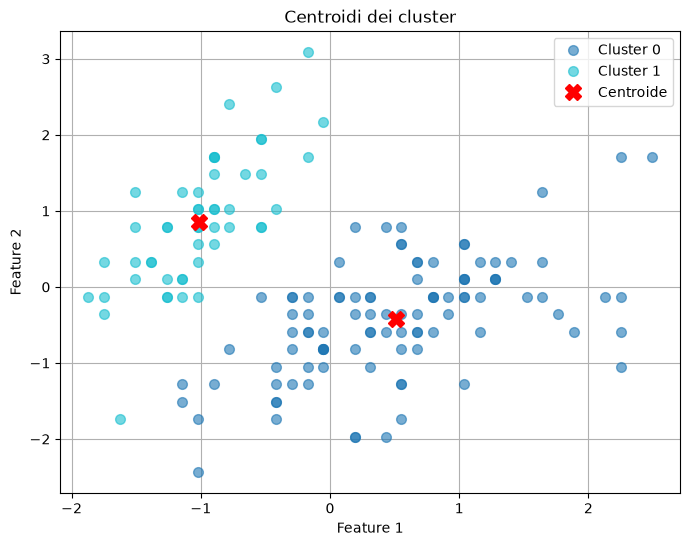

In [ ]:
plt.figure(figsize=(8,6))
labels_unique = set(kmeans_labels)
colors = [plt.cm.tab10(each) for each in np.linspace(0,1,len(labels_unique))]

for k, col in zip(labels_unique, colors):

    class_mask = (kmeans_labels == k)
    xy = X_std[class_mask]
    plt.plot(xy[:,0], xy[:,1], "o", color = col, markersize = 7, label = f"Cluster {k}", alpha = 0.6)
    
centroidi= kmeans_finale.cluster_centers_
plt.plot(centroidi[:,0], centroidi[:,1], "X", color = "red", markersize = 12, label ="Centroide")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Centroidi dei cluster")
plt.legend()
plt.grid(True)
plt.show()

                